# Laboratorio 2: distancia focal del espejo cóncavo

Datos del Cuadro 1 (apéndice C de la guía). La flecha de la fuente está en 0 cm del riel y mide hₒ = 2 cm. El fabricante indica f = 20 cm para la cara cóncava.

Calculamos f de dos maneras: con la ecuación del espejo fila por fila, y con el ajuste lineal de M contra dᵢ que pide la sección 3 de la guía.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATOS = Path("../datos")
FIGURAS = Path("../figuras")
FIGURAS.mkdir(exist_ok=True)

F_ACEPTADA = 20.0  # cm, valor del fabricante
H_OBJETO = 2.0     # cm, altura de la flecha
U_REGLA = 0.05     # cm, mitad de la menor división de la regla (1 mm)

In [2]:
c1 = pd.read_csv(DATOS / "cuadro1_concavo.csv")
c1["M"] = -c1["hi_cm"] / H_OBJETO  # la imagen sale invertida, M < 0
c1

,n,d0_cm,di_cm,hi_cm,M
0,1,52.0,32.0,1.1,-0.55
1,2,45.0,35.0,1.6,-0.80
2,3,48.0,34.0,1.4,-0.70
3,4,57.0,31.0,1.1,-0.55
4,5,62.0,29.0,1.0,-0.50
5,6,65.5,28.5,0.9,-0.45
6,7,70.0,28.0,0.8,-0.40
7,8,73.0,27.0,0.8,-0.40
8,9,79.0,27.0,0.7,-0.35
9,10,91.0,25.0,0.6,-0.30


## 1. Focal con la ecuación del espejo

De 1/d₀ + 1/dᵢ = 1/f se despeja f = d₀·dᵢ / (d₀ + dᵢ) para cada fila. Este cálculo solo usa distancias.

In [3]:
c1["f_cm"] = c1["d0_cm"] * c1["di_cm"] / (c1["d0_cm"] + c1["di_cm"])

f_media = c1["f_cm"].mean()
f_std = c1["f_cm"].std(ddof=1)
u_f_media = f_std / np.sqrt(len(c1))
err_f_media = abs(f_media - F_ACEPTADA) / F_ACEPTADA * 100

print(f"f por fila: de {c1['f_cm'].min():.2f} a {c1['f_cm'].max():.2f} cm")
print(f"f promedio = {f_media:.2f} ± {u_f_media:.2f} cm (desviación estándar {f_std:.2f} cm)")
print(f"Error respecto a {F_ACEPTADA:.0f} cm: {err_f_media:.1f} %")

f por fila: de 19.61 a 20.12 cm
f promedio = 19.85 ± 0.05 cm (desviación estándar 0.17 cm)
Error respecto a 20 cm: 0.7 %


## 2. Por qué M contra dᵢ da una recta

Partimos de M = −dᵢ/d₀ y reemplazamos 1/d₀ = 1/f − 1/dᵢ:

$$M = -d_i\left(\frac{1}{f} - \frac{1}{d_i}\right) = 1 - \frac{d_i}{f}$$

Si ajustamos M = a·dᵢ + b, la pendiente debe ser a = −1/f y el intercepto b = 1. De la pendiente sale f = −1/a y R = 2f. El intercepto queda como control: si sale lejos de 1, algo falló en la medición.

In [4]:
x = c1["di_cm"].to_numpy()
y = c1["M"].to_numpy()

(a, b), cov = np.polyfit(x, y, 1, cov=True)
u_a, u_b = np.sqrt(np.diag(cov))

y_ajuste = a * x + b
r2 = 1 - np.sum((y - y_ajuste) ** 2) / np.sum((y - y.mean()) ** 2)

f_ajuste = -1 / a
u_f_ajuste = u_a / a**2
R_ajuste = 2 * f_ajuste
u_R_ajuste = 2 * u_f_ajuste
err_f_ajuste = abs(f_ajuste - F_ACEPTADA) / F_ACEPTADA * 100

print(f"M = ({a:.4f} ± {u_a:.4f}) dᵢ + ({b:.3f} ± {u_b:.3f})")
print(f"R² = {r2:.3f}")
print(f"f = {f_ajuste:.1f} ± {u_f_ajuste:.1f} cm (error {err_f_ajuste:.1f} % respecto a {F_ACEPTADA:.0f} cm)")
print(f"R = {R_ajuste:.1f} ± {u_R_ajuste:.1f} cm")

M = (-0.0471 ± 0.0035) dᵢ + (0.896 ± 0.104)
R² = 0.958
f = 21.2 ± 1.6 cm (error 6.2 % respecto a 20 cm)
R = 42.5 ± 3.1 cm


## 3. Gráfica

Las barras de error salen de la resolución de la regla (±0.05 cm) en hᵢ y en hₒ. La línea discontinua es la recta que predice la teoría con f = 20 cm.

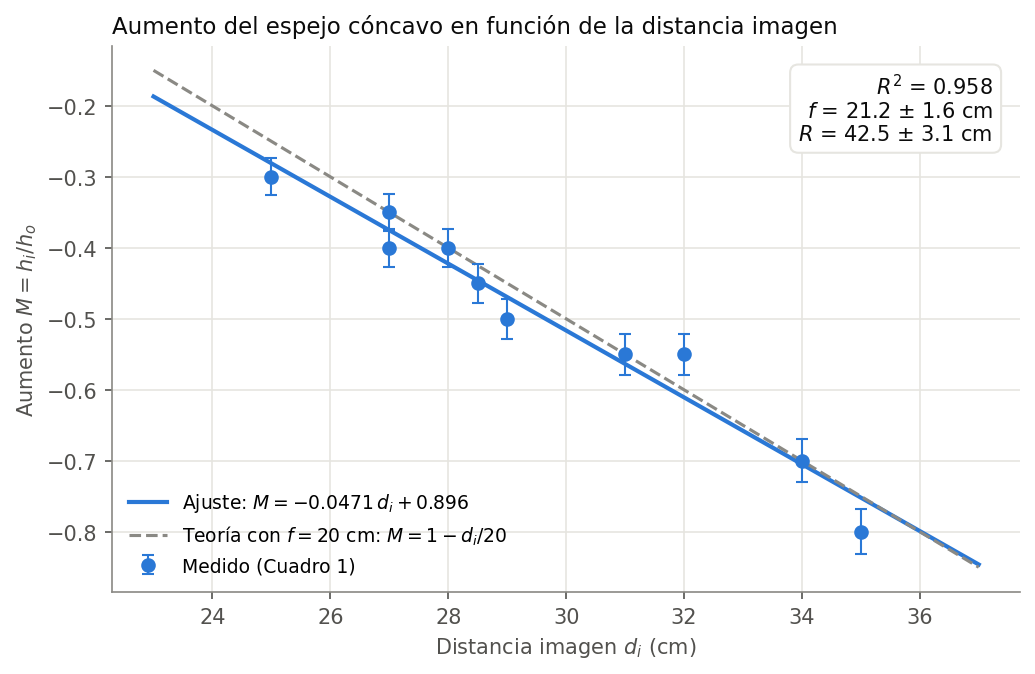

In [5]:
AZUL = "#2a78d6"
GRIS = "#8a8984"
TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
REJILLA = "#e6e5e0"

u_M = np.abs(y) * np.sqrt((U_REGLA / c1["hi_cm"]) ** 2 + (U_REGLA / H_OBJETO) ** 2)
xx = np.linspace(23, 37, 100)

fig, ax = plt.subplots(figsize=(7, 4.6), dpi=150)
ax.errorbar(x, y, yerr=u_M, fmt="o", ms=6, color=AZUL, ecolor=AZUL,
            elinewidth=1, capsize=3, zorder=3, label="Medido (Cuadro 1)")
ax.plot(xx, a * xx + b, color=AZUL, lw=2,
        label=rf"Ajuste: $M = {a:.4f}\,d_i + {b:.3f}$")
ax.plot(xx, 1 - xx / F_ACEPTADA, color=GRIS, lw=1.5, ls="--",
        label=r"Teoría con $f = 20$ cm: $M = 1 - d_i/20$")

ax.text(0.97, 0.95,
        f"$R^2$ = {r2:.3f}\n$f$ = {f_ajuste:.1f} ± {u_f_ajuste:.1f} cm\n$R$ = {R_ajuste:.1f} ± {u_R_ajuste:.1f} cm",
        transform=ax.transAxes, ha="right", va="top", fontsize=10, color=TINTA,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=REJILLA))

ax.set_xlabel(r"Distancia imagen $d_i$ (cm)", color=TINTA_2)
ax.set_ylabel(r"Aumento $M = h_i / h_o$", color=TINTA_2)
ax.set_title("Aumento del espejo cóncavo en función de la distancia imagen",
             loc="left", fontsize=11, color=TINTA)
ax.grid(color=REJILLA, lw=0.8)
ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
for lado in ("left", "bottom"):
    ax.spines[lado].set_color(GRIS)
ax.tick_params(colors=TINTA_2)
ax.legend(loc="lower left", frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(FIGURAS / "M_vs_di_ajuste.png", bbox_inches="tight")
plt.show()

## 4. Control con el intercepto fijo en 1

La teoría fija el intercepto en 1. Si lo imponemos y ajustamos solo la pendiente (M − 1 = a·dᵢ), el ajuste tiene un parámetro menos y la pendiente queda mejor determinada.

In [6]:
a1 = np.sum((y - 1) * x) / np.sum(x**2)
res1 = y - (1 + a1 * x)
u_a1 = np.sqrt(np.sum(res1**2) / (len(x) - 1) / np.sum(x**2))
r2_1 = 1 - np.sum(res1**2) / np.sum((y - y.mean()) ** 2)

f1 = -1 / a1
u_f1 = u_a1 / a1**2
err_f1 = abs(f1 - F_ACEPTADA) / F_ACEPTADA * 100

print(f"M = 1 + ({a1:.4f} ± {u_a1:.4f}) dᵢ")
print(f"R² = {r2_1:.3f}")
print(f"f = {f1:.1f} ± {u_f1:.1f} cm (error {err_f1:.1f} %), R = {2*f1:.1f} ± {2*u_f1:.1f} cm")

M = 1 + (-0.0506 ± 0.0004) dᵢ
R² = 0.953
f = 19.8 ± 0.1 cm (error 1.1 %), R = 39.6 ± 0.3 cm


## 5. De dónde viene el error

Comparamos el aumento medido con las alturas (hᵢ/hₒ) contra el que predicen las distancias de la misma fila (−dᵢ/d₀). Si las distancias están bien medidas, la diferencia viene de medir hᵢ.

In [7]:
comp = pd.DataFrame({
    "d0_cm": c1["d0_cm"],
    "di_cm": c1["di_cm"],
    "hi_cm": c1["hi_cm"],
    "M_alturas": y,
    "M_distancias": -c1["di_cm"] / c1["d0_cm"],
    "u_M": u_M,
})
comp["diferencia"] = comp["M_alturas"] - comp["M_distancias"]
comp["fuera_de_incertidumbre"] = comp["diferencia"].abs() > comp["u_M"]
comp["u_relativa_hi_%"] = U_REGLA / comp["hi_cm"] * 100
comp.round(3)

,d0_cm,di_cm,hi_cm,M_alturas,M_distancias,u_M,diferencia,fuera_de_incertidumbre,u_relativa_hi_%
0,52.0,32.0,1.1,-0.55,-0.615,0.029,0.065,True,4.545
1,45.0,35.0,1.6,-0.80,-0.778,0.032,-0.022,False,3.125
2,48.0,34.0,1.4,-0.70,-0.708,0.031,0.008,False,3.571
3,57.0,31.0,1.1,-0.55,-0.544,0.029,-0.006,False,4.545
4,62.0,29.0,1.0,-0.50,-0.468,0.028,-0.032,True,5.000
5,65.5,28.5,0.9,-0.45,-0.435,0.027,-0.015,False,5.556
6,70.0,28.0,0.8,-0.40,-0.400,0.027,0.000,False,6.250
7,73.0,27.0,0.8,-0.40,-0.370,0.027,-0.030,True,6.250
8,79.0,27.0,0.7,-0.35,-0.342,0.026,-0.008,False,7.143
9,91.0,25.0,0.6,-0.30,-0.275,0.026,-0.025,False,8.333


In [8]:
print(f"Filas donde las alturas no cuadran con las distancias: {comp['fuera_de_incertidumbre'].sum()} de {len(comp)}")
print(f"Incertidumbre relativa de hᵢ: de {comp['u_relativa_hi_%'].min():.0f} % a {comp['u_relativa_hi_%'].max():.0f} %")
print(f"Dispersión de f por distancias: {f_std / f_media * 100:.1f} %")

Filas donde las alturas no cuadran con las distancias: 3 de 10
Incertidumbre relativa de hᵢ: de 3 % a 8 %
Dispersión de f por distancias: 0.9 %


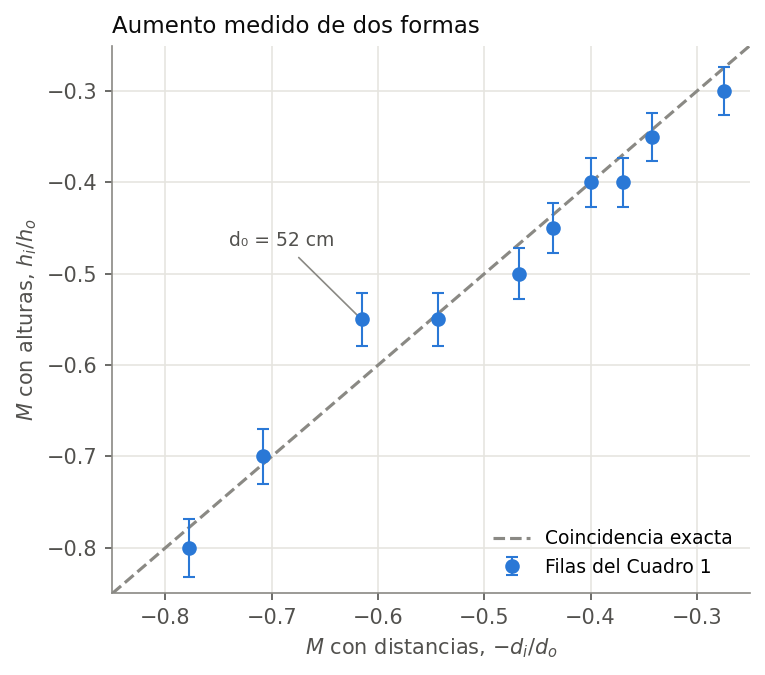

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 4.6), dpi=150)
lim = [-0.85, -0.25]
ax.plot(lim, lim, color=GRIS, lw=1.5, ls="--", label="Coincidencia exacta")
ax.errorbar(comp["M_distancias"], comp["M_alturas"], yerr=comp["u_M"], fmt="o", ms=6,
            color=AZUL, ecolor=AZUL, elinewidth=1, capsize=3, zorder=3, label="Filas del Cuadro 1")
fila_52 = comp["d0_cm"] == 52
ax.annotate("d₀ = 52 cm", xy=(comp.loc[fila_52, "M_distancias"].item(), comp.loc[fila_52, "M_alturas"].item()),
            xytext=(-0.74, -0.47), color=TINTA_2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8))
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel(r"$M$ con distancias, $-d_i/d_o$", color=TINTA_2)
ax.set_ylabel(r"$M$ con alturas, $h_i/h_o$", color=TINTA_2)
ax.set_title("Aumento medido de dos formas", loc="left", fontsize=11, color=TINTA)
ax.grid(color=REJILLA, lw=0.8); ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
for lado in ("left", "bottom"):
    ax.spines[lado].set_color(GRIS)
ax.tick_params(colors=TINTA_2)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "M_alturas_vs_distancias.png", bbox_inches="tight")
plt.show()

## 6. Prueba de la ecuación del espejo solo con distancias

La ecuación del espejo se puede escribir como una recta entre los inversos de las distancias:

$$\frac{1}{d_i} = -\frac{1}{d_o} + \frac{1}{f}$$

Si la ecuación se cumple, la pendiente de 1/dᵢ contra 1/d₀ tiene que salir −1, y el intercepto es 1/f. Esta prueba no usa las alturas, así que no arrastra el error de la regla sobre hᵢ.

In [10]:
xi = 1 / c1["d0_cm"].to_numpy()
yi = 1 / c1["di_cm"].to_numpy()

(s, c), cov_i = np.polyfit(xi, yi, 1, cov=True)
u_s, u_c = np.sqrt(np.diag(cov_i))
r2_i = 1 - np.sum((yi - (s * xi + c)) ** 2) / np.sum((yi - yi.mean()) ** 2)

f_inv = 1 / c
u_f_inv = u_c / c**2

print(f"1/dᵢ = ({s:.3f} ± {u_s:.3f})·(1/d₀) + ({c:.4f} ± {u_c:.4f}) cm⁻¹")
print(f"R² = {r2_i:.3f}")
print(f"Pendiente esperada −1: diferencia de {abs(s + 1) * 100:.1f} %")
print(f"f = {f_inv:.1f} ± {u_f_inv:.1f} cm (error {abs(f_inv - F_ACEPTADA) / F_ACEPTADA * 100:.1f} %)")

1/dᵢ = (-0.996 ± 0.042)·(1/d₀) + (0.0503 ± 0.0007) cm⁻¹
R² = 0.986
Pendiente esperada −1: diferencia de 0.4 %
f = 19.9 ± 0.3 cm (error 0.6 %)


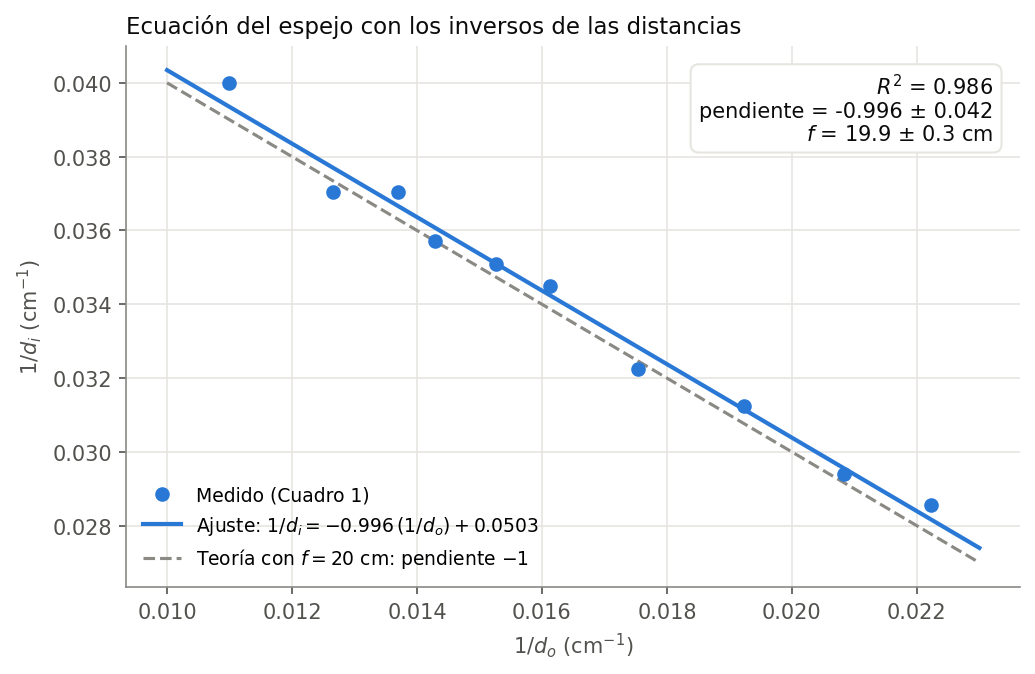

In [11]:
xx_i = np.linspace(0.010, 0.023, 100)
fig, ax = plt.subplots(figsize=(7, 4.6), dpi=150)
ax.plot(xi, yi, "o", ms=6, color=AZUL, zorder=3, label="Medido (Cuadro 1)")
ax.plot(xx_i, s * xx_i + c, color=AZUL, lw=2,
        label=rf"Ajuste: $1/d_i = {s:.3f}\,(1/d_o) + {c:.4f}$")
ax.plot(xx_i, -xx_i + 1 / F_ACEPTADA, color=GRIS, lw=1.5, ls="--",
        label=r"Teoría con $f = 20$ cm: pendiente $-1$")
ax.text(0.97, 0.95,
        f"$R^2$ = {r2_i:.3f}\npendiente = {s:.3f} ± {u_s:.3f}\n$f$ = {f_inv:.1f} ± {u_f_inv:.1f} cm",
        transform=ax.transAxes, ha="right", va="top", fontsize=10, color=TINTA,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=REJILLA))
ax.set_xlabel(r"$1/d_o$ (cm$^{-1}$)", color=TINTA_2)
ax.set_ylabel(r"$1/d_i$ (cm$^{-1}$)", color=TINTA_2)
ax.set_title("Ecuación del espejo con los inversos de las distancias", loc="left", fontsize=11, color=TINTA)
ax.grid(color=REJILLA, lw=0.8); ax.set_axisbelow(True)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
for lado in ("left", "bottom"):
    ax.spines[lado].set_color(GRIS)
ax.tick_params(colors=TINTA_2)
ax.legend(loc="lower left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "inversos_1_di_vs_1_d0.png", bbox_inches="tight")
plt.show()

## Resumen

La ecuación del espejo aplicada fila por fila da f = 19.85 ± 0.05 cm, a 0.7 % del valor del fabricante. Las diez filas caen entre 19.6 y 20.1 cm.

El ajuste lineal de M contra dᵢ da M = −0.0471·dᵢ + 0.896 con R² = 0.958. De la pendiente sale f = 21.2 ± 1.6 cm y R = 42.5 ± 3.1 cm. La diferencia con 20 cm (6.2 %) queda dentro de la incertidumbre del ajuste, y el intercepto (0.90 ± 0.10) es compatible con el 1 que predice la teoría. Si se fija el intercepto en 1, la pendiente da f = 19.8 ± 0.1 cm.

El ajuste es menos preciso que el cálculo por distancias porque usa hᵢ, que mide entre 0.6 y 1.6 cm con una regla de 1 mm: eso da entre 3 % y 8 % de incertidumbre por punto, sin contar que el borde de la imagen en el papel no es del todo nítido. En tres filas (d₀ = 52, 62 y 73 cm) la altura medida no cuadra con la que predicen sus distancias. La de 52 cm es la que más se aleja: 1.1 cm medido contra 1.23 cm esperado.

La recta de 1/dᵢ contra 1/d₀, que solo usa distancias, tiene pendiente −0.996 ± 0.042 y R² = 0.986. La teoría pide −1, así que los datos cumplen la ecuación del espejo, y de su intercepto sale f = 19.9 ± 0.3 cm.